# EllSeg segmentation validation on TEyeD (Dikablis) — prediction vs. ground truth

Segmentation only: the pretrained EllSeg network is run on every frame and its iris/pupil mask is compared with the ground-truth mask. Your wavelet eye-finder crop is kept (found per video, then the same box is applied to the frames and the ground truth); no blink detection, no gaze / eyeball model, no signals.

## 0. Config + setup

In [19]:
# ===================== CONFIG + SETUP =====================
import os, re, sys, gc, time, subprocess, warnings, traceback, argparse
from pathlib import Path
import numpy as np, pandas as pd, cv2
warnings.filterwarnings("ignore")

# ---------------- what to run ----------------
DATA_ROOT   = "/kaggle/input"      # searched recursively for *.npz ('lm_landmarks' folders are skipped)
VIDEO_REGEX = None                 # e.g. r"^DikablisSS_"  -> only videos whose file name matches
MAX_VIDEOS  = None                 # e.g. 3 for a smoke test, None = every video
MAX_FRAMES_PER_VIDEO = None        # e.g. 600 = only the first 600 frames of each video, None = all
RESUME      = False                 # skip videos that are already in per_video_metrics.csv
USE_CROP    = False                 # True = your wavelet eye finder + 4:3 crop (per video). False = whole frame goes to the network.

# ---------------- wavelet crop settings (identical to your Cell 1) ----------------
N_SAMPLES = 60           # frames analysed by the eye finder
CROP_SCALE = 2.5         # crop width = CROP_SCALE x detected eye width (bigger = looser crop)
MIN_CROP_FRAC = 0.4      # crop never narrower than this fraction of the biggest possible 4:3 window
WAVELET, LEVELS = "db2", 3
ANALYSIS_W = 256

# ---------------- npz layout (None = auto-detect, set only if the inspection cell picked the wrong arrays) ----------------
IMG_KEY  = None                    # key of the image array, e.g. "images"
MASK_KEY = None                    # key of a single multi-class mask array, e.g. "masks"
PUPIL_KEY = None                   # separate binary pupil mask, e.g. "pupil_seg_2D.mp4_path"  (None = auto: key containing "pupil")
IRIS_KEY  = None                   # separate binary iris mask,  e.g. "iris_seg_2D.mp4_path"   (None = auto: key containing "iris")
PUPIL_LABELS = None                # e.g. [3]  -> label values that are PUPIL in a single multi-class GT mask (None = auto)
IRIS_LABELS  = None                # e.g. [2]  -> label values that are IRIS  in a single multi-class GT mask (None = auto)

# ---------------- EllSeg ----------------
WEIGHTS     = "all.git_ok"         # pretrained weights shipped inside the repo
ELLIPSES    = 1                    # only affects EllSeg's ellipse output, which is NOT used here
SKIP_RANSAC = 0                    # 0 = exactly as before. (1 may be faster; segmentation does not depend on it)
NET_H, NET_W = 240, 320            # EllSeg network grid; the (cropped) frame is resized to this

# ---------------- metric settings ----------------
PRESENCE_MIN_PX = 40               # a pupil counts as "present" if its mask has >= this many px on the 240x320 grid (= 10 px on 120x160)
N_QC_FRAMES     = 40               # frames per video stored for the visual QC cell (half evenly spaced, half worst IoU)

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUT_ROOT = WORK / "validation_ellseg_seg"
for _d in ["per_frame", "seg_qc", "logs"]:
    (OUT_ROOT / _d).mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT_ROOT / "per_video_metrics.csv"
ERRORS_CSV  = OUT_ROOT / "errors.csv"
REPO = WORK / "EllSeg"

# ---------------- get EllSeg (same NumPy patch + clone as before) ----------------
for _n, _v in [("float", float), ("int", int), ("int0", np.intp), ("mat", np.asmatrix), ("bool", bool), ("object", object)]:
    if not hasattr(np, _n): setattr(np, _n, _v)
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RSKothari/EllSeg.git", str(REPO)], check=True)
if str(REPO) not in sys.path: sys.path.insert(0, str(REPO))

try:
    import pywt
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "PyWavelets"], check=True)
    import pywt
import torch
import evaluate_ellseg as ES                       # the repo's own inference code
from modelSummary import model_dict
W_PATH = REPO / "weights" / WEIGHTS
if not W_PATH.exists() or W_PATH.stat().st_size < 1_000_000:
    print("Files in", REPO / "weights", ":", sorted(p.name for p in (REPO / "weights").glob("*")) if (REPO / "weights").exists() else "folder missing")
    raise FileNotFoundError(f"Pretrained weights not found / too small: {W_PATH}. Pick one of the files listed above via WEIGHTS = '...'")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:    netDict = torch.load(str(W_PATH), map_location=device, weights_only=False)
except TypeError: netDict = torch.load(str(W_PATH), map_location=device)
model = model_dict["ritnet_v3"]
model.load_state_dict(netDict["state_dict"], strict=True)
model.to(device).eval()
ES.args = argparse.Namespace(ellseg_ellipses=ELLIPSES, skip_ransac=SKIP_RANSAC)   # evaluate_ellseg_on_image reads this global
print("EllSeg loaded on", device, "| module:", ES.__file__)

def natural_key(p):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", Path(p).name)]

def find_npz():
    files = [p for p in Path(DATA_ROOT).rglob("*.npz") if "lm_landmarks" not in p.parts]
    if VIDEO_REGEX: files = [p for p in files if re.search(VIDEO_REGEX, p.stem)]
    files = sorted(files, key=natural_key)
    return files[:MAX_VIDEOS] if MAX_VIDEOS else files

NPZ_FILES = find_npz()
print(f"{len(NPZ_FILES)} video file(s) selected under {DATA_ROOT}" + (f"; first: {NPZ_FILES[0].name}" if NPZ_FILES else ""))

EllSeg loaded on cuda | module: /kaggle/working/EllSeg/evaluate_ellseg.py
280 video file(s) selected under /kaggle/input; first: dikablisR_1_1.npz


## 1. Helpers (npz loading, wavelet crop, EllSeg prediction)

In [20]:
# ===================== npz loading, GT labels, EllSeg prediction =====================
def _sample_unique(a, n_frames=8):
    s = a[:: max(1, len(a) // n_frames)]
    return np.unique(s.ravel()[:: max(1, s.size // 400000)])

def pick_arrays(arrs):
    """Return (image_key, mask_key). Uses IMG_KEY/MASK_KEY if set, else key names, else 'many grey levels = image, few = mask'."""
    if IMG_KEY and MASK_KEY: return IMG_KEY, MASK_KEY
    cand = {k: a for k, a in arrs.items() if isinstance(a, np.ndarray) and a.dtype != object and a.ndim >= 3 and a.shape[0] >= 1}
    if len(cand) < 2: raise ValueError(f"need an image array and a mask array (ndim>=3); found {[(k, a.shape) for k, a in arrs.items()]}")
    img_hint = re.compile(r"img|image|frame|data|video|^x$|eye", re.I); msk_hint = re.compile(r"mask|label|seg|gt|annot|^y$", re.I)
    ik = IMG_KEY or next((k for k in cand if img_hint.search(k) and not msk_hint.search(k)), None)
    mk = MASK_KEY or next((k for k in cand if msk_hint.search(k) and k != ik), None)
    if ik is None or mk is None:
        nu = {k: _sample_unique(a).size for k, a in cand.items()}
        order = sorted(nu, key=nu.get)                      # fewest distinct values first
        mk = mk or next(k for k in order if k != ik); ik = ik or next(k for k in reversed(order) if k != mk)
    return ik, mk

def to_gray_frames(a):
    """-> (N, H, W) uint8 grey frames."""
    a = np.asarray(a)
    if a.ndim == 4 and a.shape[1] in (1, 3) and a.shape[-1] not in (1, 3): a = np.transpose(a, (0, 2, 3, 1))
    if a.dtype != np.uint8:
        a = a.astype(np.float32)
        if a.max() <= 1.0 + 1e-6: a = a * 255.0
        a = np.clip(a, 0, 255).astype(np.uint8)
    if a.ndim == 4:
        if a.shape[-1] == 1: a = a[..., 0]
        else: a = np.clip(a[..., :3].astype(np.float32) @ np.array([0.299, 0.587, 0.114], np.float32), 0, 255).astype(np.uint8)
    return np.ascontiguousarray(a)

def to_label_frames(m):
    m = np.asarray(m)
    if m.ndim == 4:
        if m.shape[-1] == 1: m = m[..., 0]
        elif m.shape[1] <= 8 and m.shape[-1] > 8: m = np.moveaxis(m, 1, -1).argmax(-1)      # one-hot, channel first
        elif m.shape[-1] <= 8: m = m.argmax(-1)                                              # one-hot, channel last
        else: raise ValueError(f"cannot interpret mask shape {m.shape}")
    return m.astype(np.int32)

LABEL_MAP = None                                            # (pupil_values, iris_values, why) - decided once on the first file
def decide_label_map(lab):
    if PUPIL_LABELS is not None: return list(PUPIL_LABELS), list(IRIS_LABELS or []), "user override"
    vals, cnts = np.unique(lab[:: max(1, len(lab) // 50)], return_counts=True)
    present = set(int(v) for v in vals)
    if present <= {0, 1, 2, 3} and 3 in present: return [3], [2], "labels {0 bg, 1 sclera, 2 iris, 3 pupil}"
    if present <= {0, 1, 2} and 2 in present:    return [2], [1], "labels {0 bg, 1 iris, 2 pupil} (EllSeg convention)"
    nz = sorted([(int(c), int(v)) for v, c in zip(vals, cnts) if v != 0])                    # smallest area first
    if len(nz) == 1: return [nz[0][1]], [], "single foreground label -> pupil only"
    return [nz[0][1]], [nz[1][1]], "by area: smallest label = pupil, next = iris (CHECK this!)"

def to_ellseg_labels(lab):
    out = np.zeros(lab.shape, np.uint8)
    out[np.isin(lab, LABEL_MAP[1])] = 1                     # iris
    out[np.isin(lab, LABEL_MAP[0])] = 2                     # pupil
    return out

def load_video(path, max_frames=None):
    """-> dict(frames=(N,H,W) uint8 grey, labels=(N,H,W) uint8 {0 bg, 1 iris, 2 pupil}, raw_labels, keys...)"""
    global LABEL_MAP
    z = np.load(path, allow_pickle=True); arrs = {k: z[k] for k in z.files}
    is3d = lambda k: isinstance(arrs[k], np.ndarray) and arrs[k].dtype != object and arrs[k].ndim >= 3
    pk = PUPIL_KEY or next((k for k in arrs if re.search(r"pupil", k, re.I) and is3d(k)), None)
    ik_ = IRIS_KEY or next((k for k in arrs if re.search(r"iris", k, re.I) and is3d(k)), None)
    if pk and ik_ and not MASK_KEY:                          # separate binary masks (TEyeD npz): merge into 0 bg / 1 iris / 2 pupil
        ik = IMG_KEY or next(k for k in arrs if re.search(r"video|img|image|frame", k, re.I) and is3d(k))
        img = to_gray_frames(arrs[ik]); pm, im = to_label_frames(arrs[pk]) > 0, to_label_frames(arrs[ik_]) > 0
        n = min(len(img), len(pm), len(im))
        msk = np.zeros(pm.shape, np.uint8)[:n]; msk[im[:n]] = 1; msk[pm[:n]] = 2                 # pupil wins where both are set
        mk = f"{ik_} + {pk}"; LABEL_MAP = LABEL_MAP or ([2], [1], "separate binary masks: iris -> 1, pupil -> 2")
        ready = True
    else:
        ik, mk = pick_arrays(arrs)
        img, msk = to_gray_frames(arrs[ik]), to_label_frames(arrs[mk]); ready = False
    n = min(len(img), len(msk))
    if max_frames: n = min(n, int(max_frames))
    img, msk = img[:n], msk[:n]
    H, W = min(img.shape[1], msk.shape[1]), min(img.shape[2], msk.shape[2])
    img, msk = img[:, :H, :W], msk[:, :H, :W]
    if LABEL_MAP is None:
        LABEL_MAP = decide_label_map(msk); print(f"[label map] pupil={LABEL_MAP[0]} iris={LABEL_MAP[1]}  ({LABEL_MAP[2]})")
    if not USE_CROP and abs(W / H - 4 / 3) > 0.02: print(f"WARNING: frame is {W}x{H}, not 4:3 - the network will see a stretched image")
    return dict(frames=img, labels=msk if ready else to_ellseg_labels(msk), raw_labels=msk, img_key=ik, mask_key=mk,
                keys={k: (tuple(a.shape), str(a.dtype)) for k, a in arrs.items() if isinstance(a, np.ndarray)})

# ---------- your wavelet eye finder + 4:3 crop (Cell 1 logic, working on the in-memory grey frames) ----------
def find_crop(frames):
    """frames: (N,H,W) uint8 grey. Returns dict(x0, y0, w, h, heat, cx, cy, ew, sample_idx): the 4:3 crop box (multiples of 8x6, a pure cut)."""
    N_IN, H, W = frames.shape
    want = sorted(set(np.linspace(0, max(N_IN - 1, 0), N_SAMPLES).astype(int).tolist()))
    sample_idx = [i for i in want if i < N_IN]; samples = [frames[i] for i in sample_idx]
    AW = min(ANALYSIS_W, W); AH = int(round(H * AW / W)); SC = W / AW

    def eye_score_map(grey):
        """High where the image is DARK (pupil/iris) AND rich in wavelet edge energy (lids, lashes, glints)."""
        g = cv2.resize(grey, (AW, AH), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
        coeffs = pywt.wavedec2(g, WAVELET, level=LEVELS)
        energy = np.zeros((AH, AW), np.float32)
        for (cH, cV, cD) in coeffs[1:]:
            e = np.sqrt(cH ** 2 + cV ** 2 + cD ** 2).astype(np.float32)
            energy += cv2.resize(e, (AW, AH), interpolation=cv2.INTER_LINEAR)
        energy = cv2.GaussianBlur(energy, (0, 0), max(AH, AW) / 40)
        energy /= energy.max() + 1e-9
        a = cv2.resize(coeffs[0].astype(np.float32), (AW, AH), interpolation=cv2.INTER_LINEAR)
        a = (a - a.min()) / (a.max() - a.min() + 1e-9)
        sc = (1.0 - a) * energy
        m = int(0.05 * min(AH, AW))
        sc[:m, :] = 0; sc[-m:, :] = 0; sc[:, :m] = 0; sc[:, -m:] = 0
        return sc / (sc.max() + 1e-9)

    heat = cv2.GaussianBlur(np.mean([eye_score_map(f) for f in samples], axis=0), (0, 0), max(AH, AW) / 50)
    py, px = np.unravel_index(np.argmax(heat), heat.shape)
    mask = (heat >= 0.5 * heat.max()).astype(np.uint8)
    _, lab = cv2.connectedComponents(mask)
    ys, xs = np.nonzero(lab == lab[py, px])
    ew = max(xs.max() - xs.min() + 1, (ys.max() - ys.min() + 1) * 4 / 3)
    cx, cy, ew = px * SC, py * SC, ew * SC
    k_max = int(min(W // 8, H // 6))
    k = int(np.clip(round(CROP_SCALE * ew / 8), max(1, int(MIN_CROP_FRAC * k_max)), k_max))
    cw, ch = 8 * k, 6 * k
    x0 = int(np.clip(round(cx - cw / 2), 0, W - cw)); y0 = int(np.clip(round(cy - ch / 2), 0, H - ch))
    return dict(x0=x0, y0=y0, w=cw, h=ch, heat=heat, cx=cx, cy=cy, ew=ew, sample_idx=sample_idx)

def get_box(frames):
    if USE_CROP: return find_crop(frames)
    _, H, W = frames.shape
    return dict(x0=0, y0=0, w=W, h=H, heat=None, cx=W / 2, cy=H / 2, ew=W, sample_idx=[])

def crop_to(arr, box):
    return arr[box["y0"]:box["y0"] + box["h"], box["x0"]:box["x0"] + box["w"]]

def show_crop_preview(frames, box, n_show=3):
    import matplotlib.pyplot as plt
    idx = np.linspace(0, len(frames) - 1, min(n_show, len(frames))).astype(int)
    fig, axes = plt.subplots(2, len(idx) + 1, figsize=(4 * (len(idx) + 1), 7), squeeze=False)
    if box["heat"] is not None: axes[0, 0].imshow(box["heat"], cmap="inferno"); axes[0, 0].set_title("eye-likelihood map (wavelet)")
    axes[0, 0].axis("off"); axes[1, 0].axis("off")
    for j, i in enumerate(idx, start=1):
        full = np.repeat(frames[i][..., None], 3, -1).copy()
        cv2.rectangle(full, (box["x0"], box["y0"]), (box["x0"] + box["w"], box["y0"] + box["h"]), (0, 255, 0), max(2, frames.shape[2] // 200))
        axes[0, j].imshow(full); axes[0, j].set_title(f"frame {i} + crop box"); axes[0, j].axis("off")
        axes[1, j].imshow(crop_to(frames[i], box), cmap="gray"); axes[1, j].set_title("cropped"); axes[1, j].axis("off")
    plt.tight_layout(); plt.show()

# ---------- EllSeg on one frame (same preprocessing as before: grey, 240x320 Lanczos, zero-mean / unit-std) ----------
def prep(gray):
    g = cv2.resize(gray, (NET_W, NET_H), interpolation=cv2.INTER_LANCZOS4)
    gf = g.astype(np.float32)
    return g, torch.from_numpy((gf - gf.mean()) / (gf.std() + 1e-6)).unsqueeze(0).unsqueeze(0)

@torch.no_grad()
def predict_seg(gray):
    """-> (240,320) uint8 {0 bg, 1 iris, 2 pupil}. Almost-black frames are skipped by the repo as well -> all background."""
    g, t_in = prep(gray)
    if g.max() < 20: return np.zeros((NET_H, NET_W), np.uint8)
    seg = np.asarray(ES.evaluate_ellseg_on_image(t_in.to(device), model)[0]).astype(np.uint8)
    if seg.shape != (NET_H, NET_W): seg = cv2.resize(seg, (NET_W, NET_H), interpolation=cv2.INTER_NEAREST)
    return np.minimum(seg, 2)

def gt_on_net_grid(lab):
    return cv2.resize(np.ascontiguousarray(lab), (NET_W, NET_H), interpolation=cv2.INTER_NEAREST)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 2. Inspect the data - run once and check keys / label mapping

File: dikablisR_1_1.npz
  key 'video'            shape=(206, 288, 384, 3) dtype=uint8
  key 'frames'           shape=(206,) dtype=int64
  key 'iris_seg_2D.mp4_path' shape=(206, 288, 384) dtype=uint8
  key 'pupil_seg_2D.mp4_path' shape=(206, 288, 384) dtype=uint8
  key 'lid_seg_2D.mp4_path' shape=(206, 288, 384) dtype=uint8

Auto-detected  images <- 'video'   masks <- 'iris_seg_2D.mp4_path + pupil_seg_2D.mp4_path'
Raw mask values / pixel share: {0: '89.64%', 1: '9.20%', 2: '1.16%'}
Mapped to EllSeg classes -> pupil=[2]  iris=[1]   (separate binary masks: iris -> 1, pupil -> 2)
If this is wrong, set IMG_KEY / MASK_KEY / PUPIL_LABELS / IRIS_LABELS in the config cell and re-run it (then reset LABEL_MAP = None).


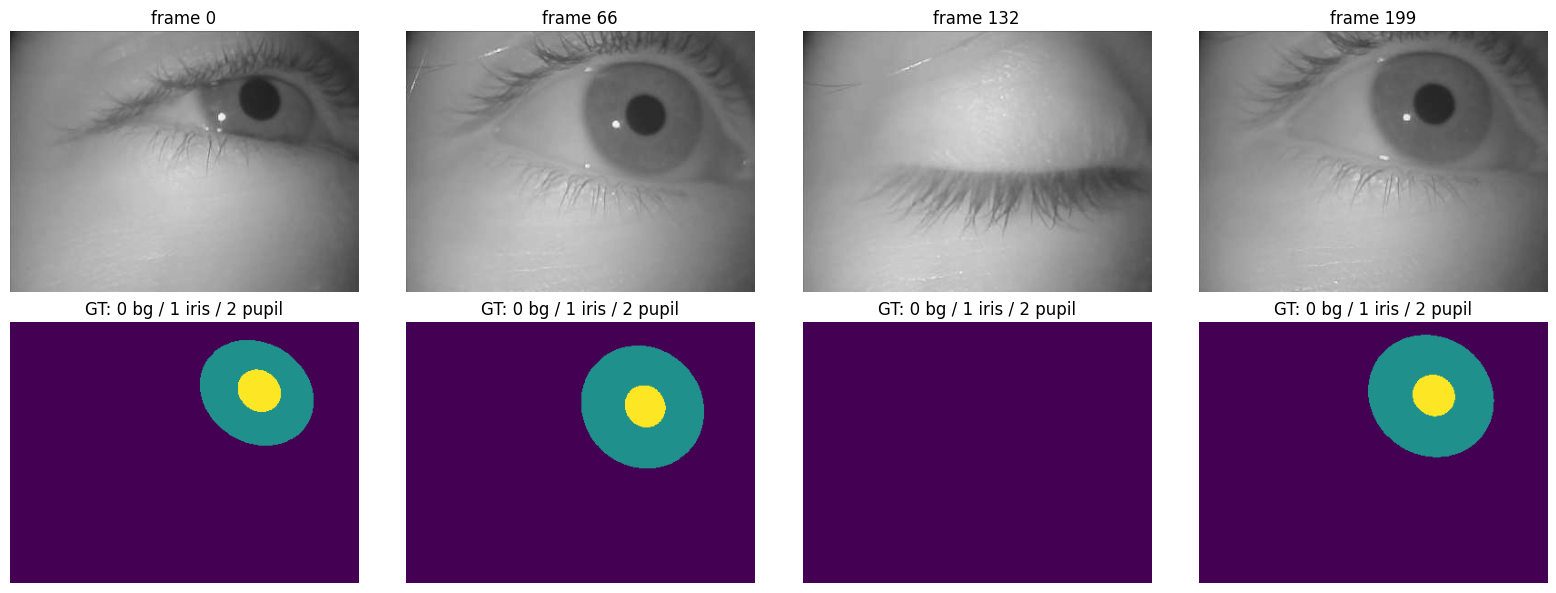

In [21]:
# ===================== INSPECT THE DATA (run once, check before the full run) =====================
f0 = NPZ_FILES[0]
z = np.load(f0, allow_pickle=True)
print("File:", f0.name)
for k in z.files:
    a = z[k]; print(f"  key {k!r:18} shape={getattr(a, 'shape', None)} dtype={getattr(a, 'dtype', type(a))}")
V = load_video(f0, max_frames=200)
print(f"\nAuto-detected  images <- {V['img_key']!r}   masks <- {V['mask_key']!r}")
vals, cnts = np.unique(V["raw_labels"], return_counts=True)
print("Raw mask values / pixel share:", {int(v): f"{100 * c / V['raw_labels'].size:.2f}%" for v, c in zip(vals, cnts)})
print(f"Mapped to EllSeg classes -> pupil={LABEL_MAP[0]}  iris={LABEL_MAP[1]}   ({LABEL_MAP[2]})")
print("If this is wrong, set IMG_KEY / MASK_KEY / PUPIL_LABELS / IRIS_LABELS in the config cell and re-run it (then reset LABEL_MAP = None).")

import matplotlib
if "ipykernel" in sys.modules: get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
idx = np.linspace(0, len(V["frames"]) - 1, 4).astype(int)
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for j, i in enumerate(idx):
    ax[0, j].imshow(V["frames"][i], cmap="gray"); ax[0, j].set_title(f"frame {i}"); ax[0, j].axis("off")
    ax[1, j].imshow(V["labels"][i], vmin=0, vmax=2, cmap="viridis"); ax[1, j].set_title("GT: 0 bg / 1 iris / 2 pupil"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

if USE_CROP:
    box = get_box(V["frames"])
    print(f"Crop box (x0, y0, w, h) = ({box['x0']}, {box['y0']}, {box['w']}, {box['h']}) of the {V['frames'].shape[2]}x{V['frames'].shape[1]} frame")
    show_crop_preview(V["frames"], box)
    print("The pupil should be inside the green box in ALL frames (open AND closed). If not, raise CROP_SCALE and re-run the config cell.")

## 3. Segmentation metrics

In [22]:
# ===================== segmentation metrics (pure comparison code) =====================
def _agree(pred, gt):
    pred, gt = np.asarray(pred, bool), np.asarray(gt, bool); n = max(len(gt), 1)
    tp, fp, fn = int((pred & gt).sum()), int((pred & ~gt).sum()), int((~pred & gt).sum()); tn = len(gt) - tp - fp - fn
    acc = (tp + tn) / n; pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n ** 2
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, accuracy=acc,
                precision=tp / (tp + fp) if tp + fp else np.nan, recall=tp / (tp + fn) if tp + fn else np.nan,
                f1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan, kappa=(acc - pe) / (1 - pe) if pe < 1 else np.nan)

def _iou_dice(inter, sP, sG):
    inter, sP, sG = inter.astype(float), sP.astype(float), sG.astype(float)
    uni = sP + sG - inter
    return np.where(uni > 0, inter / np.maximum(uni, 1), np.nan), np.where(sP + sG > 0, 2 * inter / np.maximum(sP + sG, 1), np.nan)

def frame_confusions(pred, gt):
    """3x3 confusion matrix (rows GT, cols prediction) of one frame, flattened to 9 ints."""
    return np.bincount((gt.astype(np.int64) * 3 + pred).ravel(), minlength=9)

def compare(cm9, pred_small, gt_small):
    """cm9: (N,9) per-frame confusion counts. Returns (video-level dict, per-frame DataFrame, QC arrays)."""
    N = len(cm9); cmf = cm9.reshape(N, 3, 3); cm = cmf.sum(0)                   # rows GT, cols prediction
    R = dict(n_frames=N)

    # ---- pooled pixel metrics ----
    R["pixel_accuracy"] = cm.trace() / cm.sum()
    cls_iou = [cm[c, c] / (cm[c].sum() + cm[:, c].sum() - cm[c, c]) if (cm[c].sum() + cm[:, c].sum() - cm[c, c]) else np.nan for c in range(3)]
    R.update(iou_bg=cls_iou[0], iou_iris_cm=cls_iou[1], iou_pupil_cm=cls_iou[2])
    R["miou_3class"] = float(np.nanmean([cls_iou[c] for c in range(3) if cm[c].sum() > 0]))
    for i in range(3):
        for j in range(3): R[f"cm_{i}{j}"] = int(cm[i, j])

    # ---- per-frame overlap (pupil, iris, iris+pupil) ----
    sG, sP = cmf[:, 2, :].sum(1), cmf[:, :, 2].sum(1)                            # pupil px GT / prediction
    pi, pdc = _iou_dice(cmf[:, 2, 2], sP, sG)
    iG, iP = cmf[:, 1, :].sum(1), cmf[:, :, 1].sum(1)                            # iris px
    ii, idc = _iou_dice(cmf[:, 1, 1], iP, iG)
    fG, fP = cmf[:, 1:, :].sum((1, 2)), cmf[:, :, 1:].sum((1, 2))                # iris + pupil together
    fi, _ = _iou_dice(cmf[:, 1:, 1:].sum((1, 2)), fP, fG)
    gp, gi = sG >= PRESENCE_MIN_PX, iG >= PRESENCE_MIN_PX
    pi_p, pd_p = np.where(gp, pi, np.nan), np.where(gp, pdc, np.nan)
    R.update(pupil_iou_mean=np.nanmean(pi_p) if gp.any() else np.nan, pupil_iou_median=np.nanmedian(pi_p) if gp.any() else np.nan,
             pupil_dice_mean=np.nanmean(pd_p) if gp.any() else np.nan,
             iris_iou_mean=np.nanmean(np.where(gi, ii, np.nan)) if gi.any() else np.nan,
             iris_dice_mean=np.nanmean(np.where(gi, idc, np.nan)) if gi.any() else np.nan,
             irispupil_iou_mean=np.nanmean(np.where(gi | gp, fi, np.nan)) if (gi | gp).any() else np.nan,
             pupil_iou_ge_0p5=np.nanmean(pi_p[gp] >= 0.5) if gp.any() else np.nan, pupil_iou_ge_0p75=np.nanmean(pi_p[gp] >= 0.75) if gp.any() else np.nan,
             gt_pupil_frames=int(gp.sum()), gt_pupil_frac=float(gp.mean()))

    # ---- pupil presence (GT has a pupil in the frame vs. network finds one) ----
    pp = sP >= PRESENCE_MIN_PX
    R.update({f"pupil_presence_{k}": v for k, v in _agree(pp, gp).items()})

    # ---- per-frame table ----
    fr = pd.DataFrame(dict(frame=np.arange(N), pupil_px_gt=sG, pupil_px_pred=sP, gt_pupil_present=gp, pupil_iou=pi, pupil_dice=pdc,
                           iris_px_gt=iG, iris_px_pred=iP, iris_iou=ii, irispupil_iou=fi))
    # ---- QC arrays (120x160): evenly spaced + worst frames ----
    cand = np.flatnonzero(gp)
    if cand.size:
        even = cand[np.linspace(0, cand.size - 1, min(N_QC_FRAMES // 2, cand.size)).astype(int)]
        worst = cand[np.argsort(np.nan_to_num(pi[cand], nan=0.0))[: N_QC_FRAMES // 2]]
        qi = np.unique(np.r_[even, worst])
    else: qi = np.linspace(0, N - 1, min(N_QC_FRAMES, N)).astype(int)
    qc = dict(idx=qi, seg_pred=pred_small[qi], seg_gt=gt_small[qi])
    return R, fr, qc

## 4. Run all videos (resumable: re-run this cell after a crash / timeout and it continues)

In [23]:
# ===================== RUN: every video -> wavelet crop -> EllSeg prediction vs (equally cropped) ground-truth mask =====================
def load_done():
    return pd.read_csv(RESULTS_CSV) if (RESUME and RESULTS_CSV.exists()) else pd.DataFrame()

results = load_done(); done = set(results["video"]) if len(results) else set()
errors = pd.read_csv(ERRORS_CSV).to_dict("records") if (RESUME and ERRORS_CSV.exists()) else []
t_all = time.time()
print(f"{len(NPZ_FILES)} videos, {len(done)} already done")
for vi, path in enumerate(NPZ_FILES, 1):
    name = path.stem
    if name in done: continue
    t0 = time.time()
    try:
        V = load_video(path, MAX_FRAMES_PER_VIDEO)
        N = len(V["frames"]); cm9 = np.zeros((N, 9), np.int64)
        box = get_box(V["frames"]); gtp_full = np.zeros(N, np.int64); gtp_crop = np.zeros(N, np.int64)      # GT pupil px before / after the crop
        pred_small = np.zeros((N, NET_H // 2, NET_W // 2), np.uint8); gt_small = np.zeros_like(pred_small)
        for i in range(N):
            lab_c = crop_to(V["labels"][i], box)
            gtp_full[i], gtp_crop[i] = int((V["labels"][i] == 2).sum()), int((lab_c == 2).sum())
            pred, gt = predict_seg(crop_to(V["frames"][i], box)), gt_on_net_grid(lab_c)
            cm9[i] = frame_confusions(pred, gt)
            pred_small[i], gt_small[i] = pred[::2, ::2], gt[::2, ::2]
            if (i + 1) % 200 == 0: print(f"\r  {name}: {i + 1}/{N} frames", end="", flush=True)
        free_gpu()
        R, fr, qc = compare(cm9, pred_small, gt_small)
        fr.to_csv(OUT_ROOT / "per_frame" / f"{name}.csv", index=False)
        np.savez_compressed(OUT_ROOT / "seg_qc" / f"{name}.npz", **qc)
        row = dict(video=name, family=(lambda f: f[0].upper() + f[1:])(re.match(r"[A-Za-z]+", name).group(0)), npz_path=str(path),
                   seconds=round(time.time() - t0, 1), src_w=V["frames"].shape[2], src_h=V["frames"].shape[1],
                   crop_x0=box["x0"], crop_y0=box["y0"], crop_w=box["w"], crop_h=box["h"], crop_pupil_kept=float(gtp_crop.sum() / max(gtp_full.sum(), 1))); row.update(R)
        results = pd.concat([results, pd.DataFrame([row])], ignore_index=True); results.to_csv(RESULTS_CSV, index=False)
        print(f"\r[{vi}/{len(NPZ_FILES)}] {name}: {R['n_frames']} fr | pupil IoU {R['pupil_iou_mean']:.3f} | iris IoU {R['iris_iou_mean']:.3f} | "
              f"mIoU {R['miou_3class']:.3f} | presence F1 {R['pupil_presence_f1']:.2f} | pupil kept by crop {row['crop_pupil_kept']:.3f} | {time.time() - t0:.0f}s")
    except Exception as e:
        tb = traceback.format_exc(); errors.append(dict(video=name, error=repr(e)[:300])); pd.DataFrame(errors).to_csv(ERRORS_CSV, index=False)
        (OUT_ROOT / "logs" / f"{name}_ERROR.txt").write_text(tb)
        print(f"\r[{vi}/{len(NPZ_FILES)}] {name}: FAILED -> {repr(e)[:200]}  (details in logs/{name}_ERROR.txt)")
        free_gpu()
print(f"\nDone: {len(results)} videos in results, {len(errors)} errors, {(time.time() - t_all) / 60:.1f} min this session")

280 videos, 0 already done
[1/280] dikablisR_1_1: 206 fr | pupil IoU 0.937 | iris IoU 0.914 | mIoU 0.890 | presence F1 0.93 | pupil kept by crop 1.000 | 6s
[2/280] dikablisR_1_2: 206 fr | pupil IoU 0.937 | iris IoU 0.893 | mIoU 0.888 | presence F1 0.94 | pupil kept by crop 1.000 | 6s
[3/280] DikablisSA_1_2: 208 fr | pupil IoU 0.898 | iris IoU 0.864 | mIoU 0.916 | presence F1 1.00 | pupil kept by crop 1.000 | 6s
[4/280] DikablisSA_5_2: 204 fr | pupil IoU 0.867 | iris IoU 0.845 | mIoU 0.387 | presence F1 0.16 | pupil kept by crop 1.000 | 6s
[5/280] DikablisSA_9_2: 202 fr | pupil IoU 0.893 | iris IoU 0.929 | mIoU 0.936 | presence F1 1.00 | pupil kept by crop 1.000 | 6s
[6/280] DikablisSA_9_3: 22 fr | pupil IoU 0.901 | iris IoU 0.887 | mIoU 0.903 | presence F1 0.95 | pupil kept by crop 1.000 | 1s
[7/280] DikablisSA_12_2: 203 fr | pupil IoU 0.882 | iris IoU 0.834 | mIoU 0.885 | presence F1 0.99 | pupil kept by crop 1.000 | 6s
[8/280] DikablisSA_14_2: 222 fr | pupil IoU 0.891 | iris IoU 0.90

## 5. Summary tables + plots

280 videos | 65,448 frames

=== SEGMENTATION (per-video statistics) ===
                                 n_videos   mean    std  median    p10    p90
metric                                                                       
Pixel accuracy (3 classes)            280  0.980  0.012   0.983  0.973  0.988
mIoU (bg/iris/pupil, pooled px)       280  0.920  0.046   0.927  0.896  0.948
Pupil IoU (GT-present frames)         279  0.925  0.020   0.928  0.898  0.947
Pupil IoU, median over frames         279  0.932  0.018   0.936  0.909  0.952
Pupil Dice                            279  0.960  0.013   0.962  0.945  0.973
Iris IoU                              279  0.878  0.053   0.891  0.815  0.925
Iris Dice                             279  0.932  0.035   0.940  0.891  0.960
Iris+pupil IoU                        279  0.902  0.048   0.914  0.845  0.942
Pupil IoU>=0.5 (frac of frames)       279  0.996  0.011   1.000  0.990  1.000
Pupil IoU>=0.75 (frac)                279  0.989  0.017   0.995  0.970

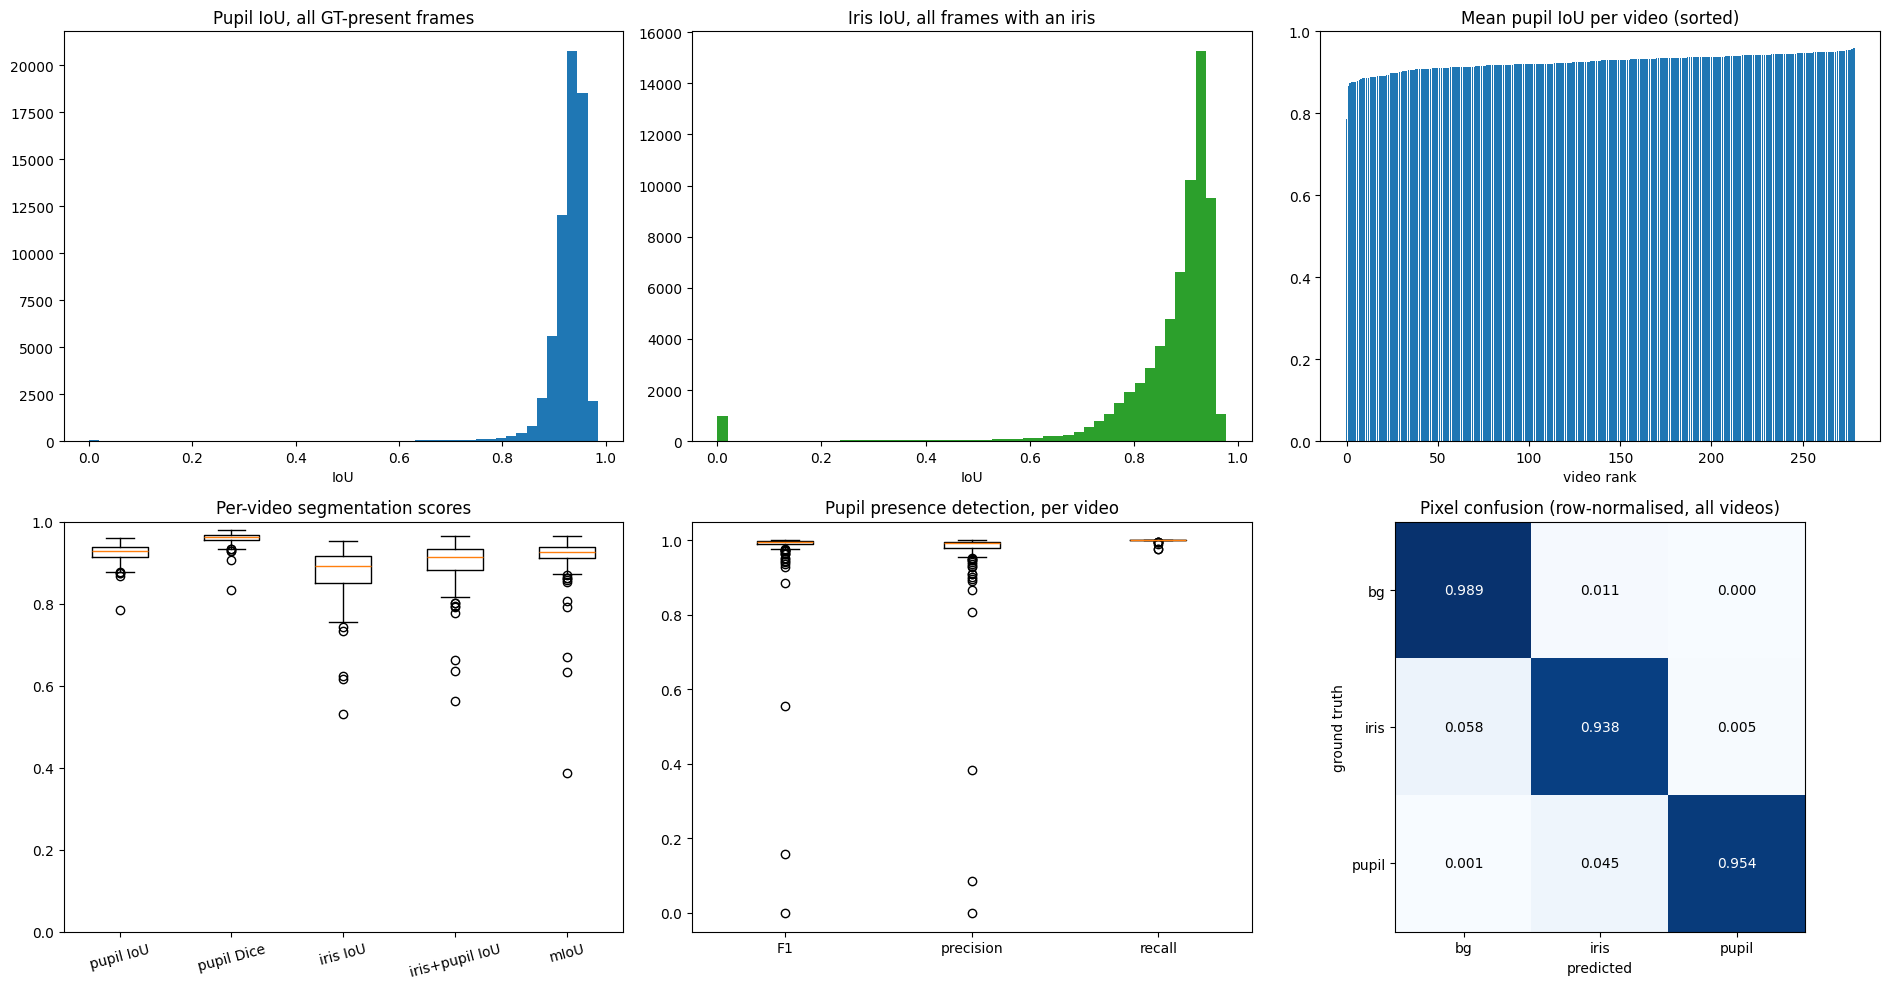


Worst 10 videos by pupil IoU:
          video  n_frames  pupil_iou_mean  iris_iou_mean  miou_3class  pupil_presence_f1  crop_pupil_kept
DikablisSS_39_1       216           0.786          0.530        0.671              0.885              1.0
 DikablisSA_5_2       204           0.867          0.845        0.387              0.158              1.0
 DikablisT_23_6       250           0.875          0.824        0.889              0.938              1.0
DikablisSA_35_2       204           0.876          0.908        0.904              0.993              1.0
DikablisSS_23_1       208           0.876          0.891        0.885              0.980              1.0
DikablisSS_22_1       225           0.877          0.872        0.903              0.996              1.0
  DikablisT_2_1       201           0.880          0.920        0.916              0.990              1.0
DikablisSA_12_2       203           0.882          0.834        0.885              0.993              1.0
DikablisSS_17_2

In [24]:
# ===================== SUMMARY + PLOTS =====================
import matplotlib
if "ipykernel" in sys.modules: get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

res = pd.read_csv(RESULTS_CSV)
fr_all = pd.concat([pd.read_csv(p).assign(video=p.stem) for p in sorted((OUT_ROOT / "per_frame").glob("*.csv"))], ignore_index=True)
print(f"{len(res)} videos | {len(fr_all):,} frames\n")

def stat_table(df, cols):
    rows = []
    for lab, c in cols:
        if c in df.columns:
            x = df[c].dropna()
            rows.append((lab, len(x), x.mean(), x.std(), x.median(), x.quantile(0.1), x.quantile(0.9)))
    return pd.DataFrame(rows, columns=["metric", "n_videos", "mean", "std", "median", "p10", "p90"]).set_index("metric").round(3)

SEG = [
    ("Pixel accuracy (3 classes)", "pixel_accuracy"),
    ("mIoU (bg/iris/pupil, pooled px)", "miou_3class"),
    ("Pupil IoU (GT-present frames)", "pupil_iou_mean"),
    ("Pupil IoU, median over frames", "pupil_iou_median"),
    ("Pupil Dice", "pupil_dice_mean"),
    ("Iris IoU", "iris_iou_mean"),
    ("Iris Dice", "iris_dice_mean"),
    ("Iris+pupil IoU", "irispupil_iou_mean"),
    ("Pupil IoU>=0.5 (frac of frames)", "pupil_iou_ge_0p5"),
    ("Pupil IoU>=0.75 (frac)", "pupil_iou_ge_0p75"),
]
PRES = [
    ("Pupil presence F1", "pupil_presence_f1"),
    ("Pupil presence precision", "pupil_presence_precision"),
    ("Pupil presence recall", "pupil_presence_recall"),
    ("Pupil presence kappa", "pupil_presence_kappa"),
    ("GT frames with pupil (frac)", "gt_pupil_frac"),
]
CROP = [("GT pupil pixels kept inside the crop (1.0 = nothing cut off)", "crop_pupil_kept"), ("Crop width (px)", "crop_w"), ("Crop width / frame width", "crop_frac")]
if "crop_w" in res.columns: res["crop_frac"] = res["crop_w"] / res["src_w"]
pd.set_option("display.width", 200)
print("=== SEGMENTATION (per-video statistics) ==="); print(stat_table(res, SEG).to_string())
print("\n=== PUPIL PRESENCE ==="); print(stat_table(res, PRES).to_string())
if USE_CROP and "crop_w" in res.columns: print("\n=== WAVELET CROP ==="); print(stat_table(res, CROP).to_string())

# ---- pooled over all frames ----
g = fr_all[fr_all["gt_pupil_present"] == 1]
cmT = res[[f"cm_{i}{j}" for i in range(3) for j in range(3)]].sum().to_numpy().reshape(3, 3)
cls = [cmT[c, c] / (cmT[c].sum() + cmT[:, c].sum() - cmT[c, c]) for c in range(3)]
print("\n=== POOLED OVER ALL FRAMES / PIXELS ===")
print(f"Pixel accuracy {cmT.trace() / cmT.sum():.4f} | IoU bg {cls[0]:.3f} iris {cls[1]:.3f} pupil {cls[2]:.3f} | mIoU {np.mean(cls):.3f}")
print(f"Pupil IoU (GT-present frames) mean {g['pupil_iou'].mean():.3f} | median {g['pupil_iou'].median():.3f} | Dice mean {g['pupil_dice'].mean():.3f}")
print(f"Iris IoU mean {fr_all['iris_iou'].mean():.3f} | Iris+pupil IoU mean {fr_all['irispupil_iou'].mean():.3f}")

pd.concat([stat_table(res, SEG), stat_table(res, PRES)] + ([stat_table(res, CROP)] if USE_CROP else [])).to_csv(OUT_ROOT / "summary_overall.csv")

# ---- per-family table (Dikablis subsets) ----
if "family" in res.columns and res["family"].nunique() > 1:
    print("\n=== PER FAMILY (mean over videos) ===")
    print(res.groupby("family")[["pupil_iou_mean", "iris_iou_mean", "miou_3class", "pupil_presence_f1"]].mean().round(3).assign(videos=res.groupby("family").size()).to_string())

# ---- plots ----
def bp(ax, data, labels, rot=0):
    ax.boxplot([d if len(d) else [np.nan] for d in data]); ax.set_xticks(range(1, len(labels) + 1)); ax.set_xticklabels(labels, rotation=rot)

fig, ax = plt.subplots(2, 3, figsize=(19, 10))
ax[0, 0].hist(g["pupil_iou"].dropna(), bins=50, color="tab:blue"); ax[0, 0].set_title("Pupil IoU, all GT-present frames"); ax[0, 0].set_xlabel("IoU")
ax[0, 1].hist(fr_all["iris_iou"].dropna(), bins=50, color="tab:green"); ax[0, 1].set_title("Iris IoU, all frames with an iris"); ax[0, 1].set_xlabel("IoU")
rs = res.sort_values("pupil_iou_mean")
ax[0, 2].bar(range(len(rs)), rs["pupil_iou_mean"], color="tab:blue"); ax[0, 2].set_ylim(0, 1)
ax[0, 2].set_title("Mean pupil IoU per video (sorted)"); ax[0, 2].set_xlabel("video rank")
bp(ax[1, 0], [res[c].dropna().to_numpy() for c in ["pupil_iou_mean", "pupil_dice_mean", "iris_iou_mean", "irispupil_iou_mean", "miou_3class"]],
   ["pupil IoU", "pupil Dice", "iris IoU", "iris+pupil IoU", "mIoU"], rot=15)
ax[1, 0].set_ylim(0, 1); ax[1, 0].set_title("Per-video segmentation scores")
bp(ax[1, 1], [res[c].dropna().to_numpy() for c in ["pupil_presence_f1", "pupil_presence_precision", "pupil_presence_recall"]], ["F1", "precision", "recall"])
ax[1, 1].set_title("Pupil presence detection, per video")
cmN = np.divide(cmT, cmT.sum(1, keepdims=True), out=np.zeros_like(cmT, dtype=float), where=cmT.sum(1, keepdims=True) != 0)
ax[1, 2].imshow(cmN, vmin=0, vmax=1, cmap="Blues")
ax[1, 2].set_xticks(range(3)); ax[1, 2].set_yticks(range(3)); ax[1, 2].set_xticklabels(["bg", "iris", "pupil"]); ax[1, 2].set_yticklabels(["bg", "iris", "pupil"])
ax[1, 2].set_xlabel("predicted"); ax[1, 2].set_ylabel("ground truth"); ax[1, 2].set_title("Pixel confusion (row-normalised, all videos)")
for i in range(3):
    for j in range(3): ax[1, 2].text(j, i, f"{cmN[i, j]:.3f}", ha="center", va="center", color="white" if cmN[i, j] > .5 else "black")
plt.tight_layout(); fig.savefig(OUT_ROOT / "plot_segmentation.png", dpi=110); plt.show()

print("\nWorst 10 videos by pupil IoU:")
print(res.nsmallest(10, "pupil_iou_mean")[["video", "n_frames", "pupil_iou_mean", "iris_iou_mean", "miou_3class", "pupil_presence_f1", "crop_pupil_kept"]].round(3).to_string(index=False))
if ERRORS_CSV.exists():
    print("\nVideos that failed:"); print(pd.read_csv(ERRORS_CSV).to_string(index=False))

## 6. Visual QC of one video

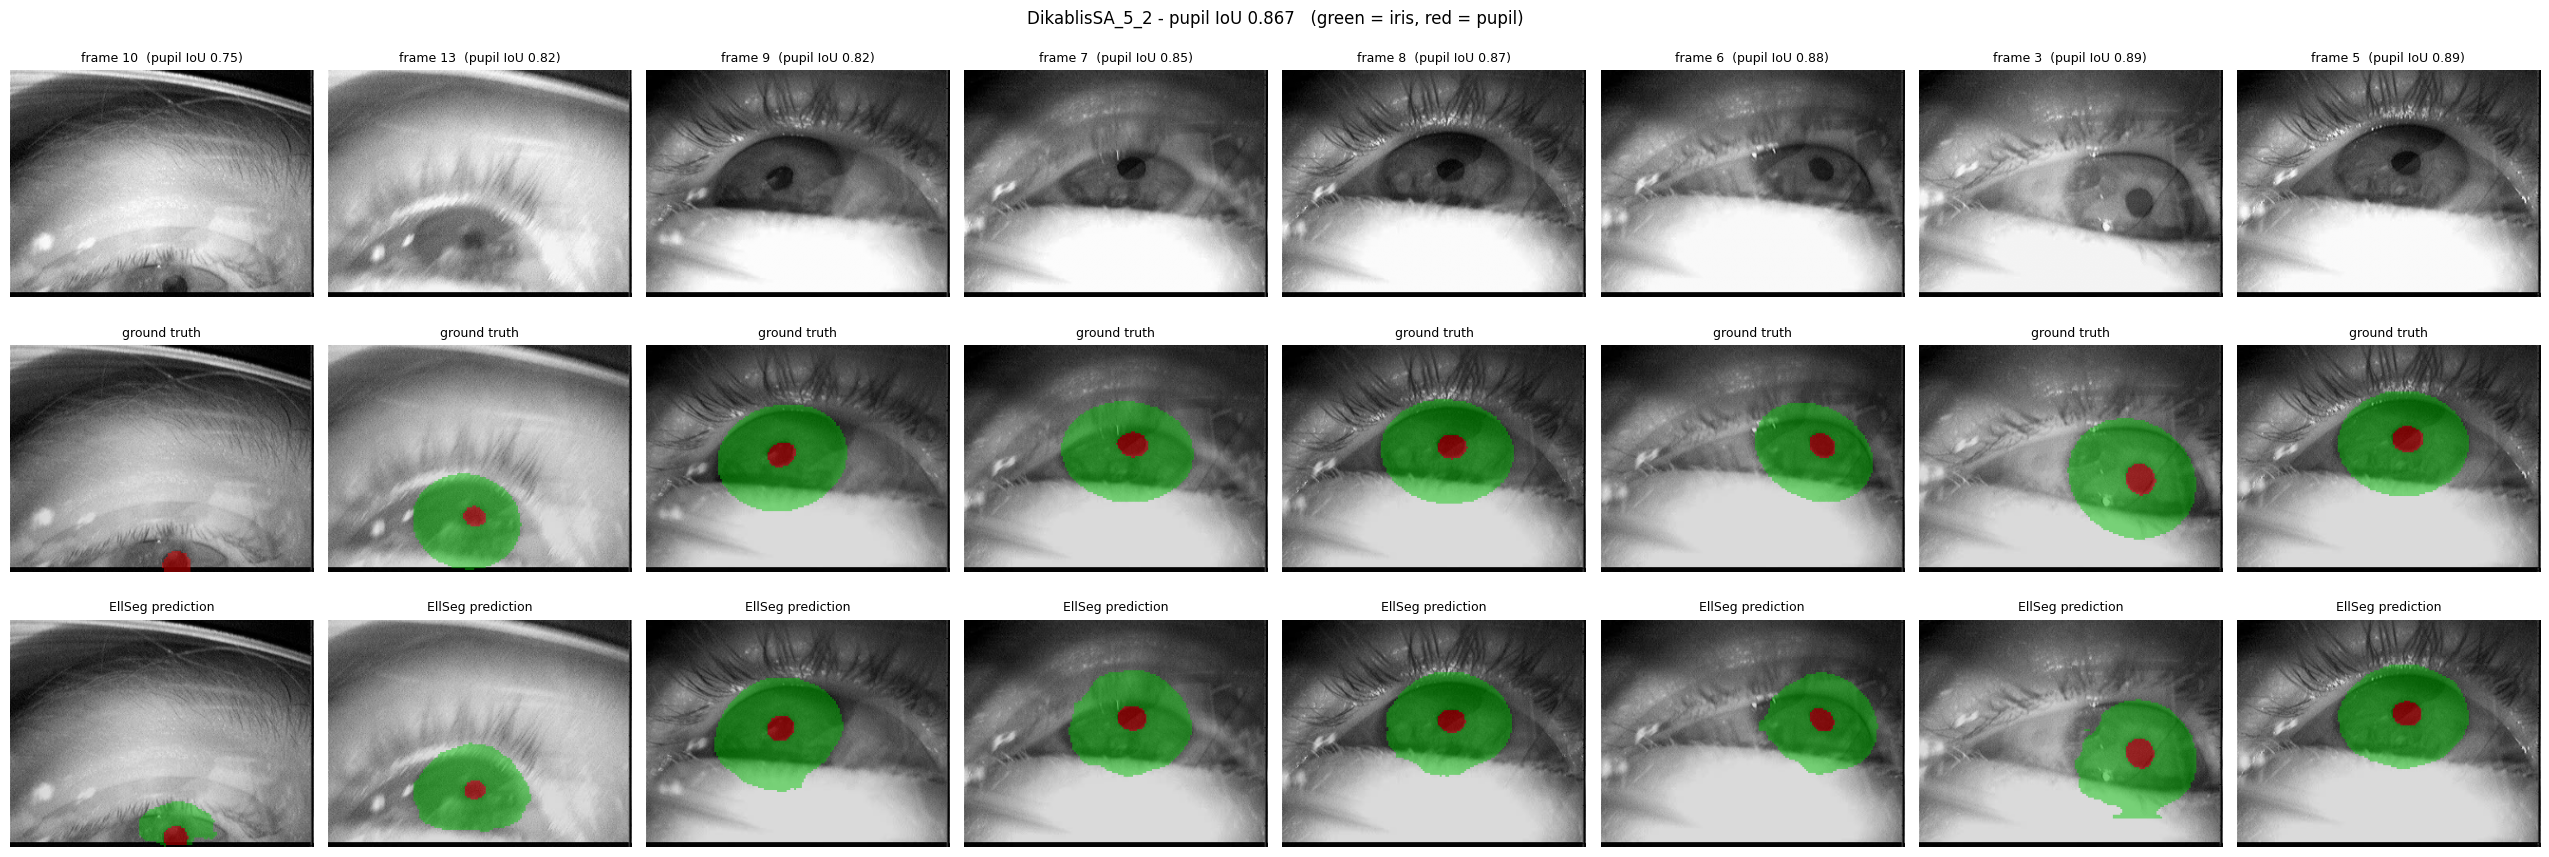

In [25]:
# ===================== VISUAL QC: ground truth vs EllSeg segmentation (on the wavelet crop) for one video =====================
import matplotlib
if "ipykernel" in sys.modules: get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
QC_VIDEO = "None"   # set to None to use the video with the lowest pupil IoU
QC_N = 8                      # frames shown
QC_WORST = True               # True = the worst frames first, False = evenly spread

res = pd.read_csv(RESULTS_CSV)
row = res[res["video"] == QC_VIDEO].iloc[0] if (QC_VIDEO and (res["video"] == QC_VIDEO).any()) else res.nsmallest(1, "pupil_iou_mean").iloc[0]
qc = np.load(OUT_ROOT / "seg_qc" / f"{row['video']}.npz"); V = load_video(Path(row["npz_path"]), MAX_FRAMES_PER_VIDEO)
box = dict(x0=int(row["crop_x0"]), y0=int(row["crop_y0"]), w=int(row["crop_w"]), h=int(row["crop_h"]))
fr = pd.read_csv(OUT_ROOT / "per_frame" / f"{row['video']}.csv").set_index("frame")
order = np.argsort(fr.loc[qc["idx"], "pupil_iou"].fillna(0).to_numpy()) if QC_WORST else np.arange(len(qc["idx"]))
pick = order[:QC_N] if QC_WORST else order[np.linspace(0, len(order) - 1, min(QC_N, len(order))).astype(int)]

def overlay(img, seg):
    o = np.repeat(img[..., None], 3, -1).astype(np.float32); big = cv2.resize(seg.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    for lab, col in [(1, (0, 200, 0)), (2, (255, 0, 0))]: o[big == lab] = 0.55 * o[big == lab] + 0.45 * np.array(col, np.float32)
    return o.astype(np.uint8)

fig, ax = plt.subplots(3, len(pick), figsize=(3.2 * len(pick), 9), squeeze=False)
for j, k in enumerate(pick):
    i = int(qc["idx"][k]); img = cv2.resize(crop_to(V["frames"][i], box), (NET_W, NET_H))
    ax[0, j].imshow(img, cmap="gray"); ax[0, j].set_title(f"frame {i}  (pupil IoU {fr.loc[i, 'pupil_iou']:.2f})", fontsize=9)
    ax[1, j].imshow(overlay(img, qc["seg_gt"][k])); ax[1, j].set_title("ground truth", fontsize=9)
    ax[2, j].imshow(overlay(img, qc["seg_pred"][k])); ax[2, j].set_title("EllSeg prediction", fontsize=9)
    for r in range(3): ax[r, j].axis("off")
plt.suptitle(f"{row['video']} - pupil IoU {row['pupil_iou_mean']:.3f}   (green = iris, red = pupil)"); plt.tight_layout(); plt.show()